# 2. Sales and category performance
Where does the revenue come from, and when?

Revenue here means item price on valid orders (canceled and unavailable orders excluded). Freight is tracked separately.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
import json
summary = json.loads((OUT / "summary.json").read_text())
pd.Series({
    "Valid orders": f"{summary['valid_orders']:,}",
    "Unique customers": f"{summary['customers']:,}",
    "Revenue (BRL)": f"{summary['revenue']:,.0f}",
    "Average order value (BRL)": f"{summary['aov']:,.2f}",
    "Peak month": summary["peak_month"],
})

Valid orders                     97,910
Unique customers                 94,707
Revenue (BRL)                13,449,530
Average order value (BRL)        137.37
Peak month                      2017-11
dtype: str

## Monthly revenue

,order_month,orders,revenue,aov,revenue_growth
10,2017-11,7423,"1,003,862.14",135.24,0.52
11,2017-12,5620,"742,183.79",132.06,-0.26
12,2018-01,7187,"945,456.29",131.55,0.27
13,2018-02,6625,"837,895.43",126.47,-0.11
14,2018-03,7168,"981,051.06",136.87,0.17
15,2018-04,6919,"993,592.98",143.60,0.01
16,2018-05,6833,"992,871.75",145.31,-0.00
17,2018-06,6145,"863,265.53",140.48,-0.13
18,2018-07,6233,"878,044.27",140.87,0.02
19,2018-08,6421,"848,860.10",132.20,-0.03


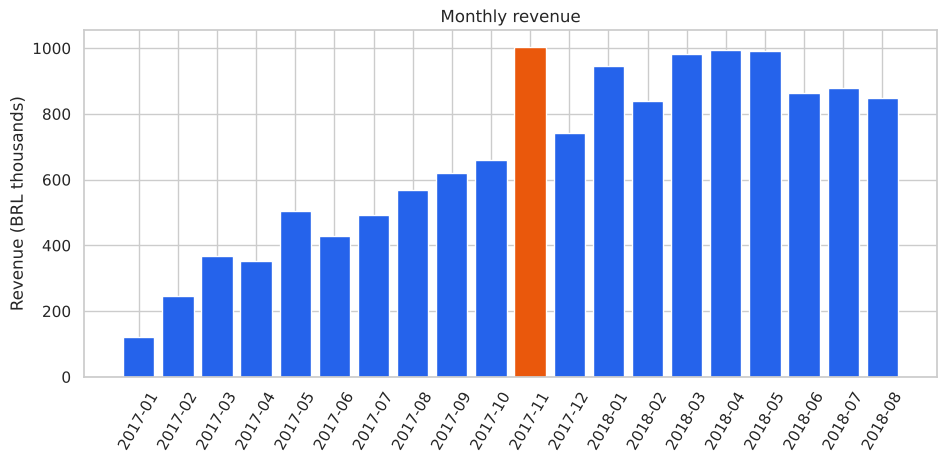

In [3]:
m = pd.read_csv(OUT / "monthly_kpis.csv")
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(m["order_month"], m["revenue"] / 1e3, color=["#ea580c" if x == "2017-11" else "#2563eb" for x in m["order_month"]])
ax.set_ylabel("Revenue (BRL thousands)"); ax.tick_params(axis="x", rotation=60)
ax.set_title("Monthly revenue")
m[["order_month", "orders", "revenue", "aov", "revenue_growth"]].tail(10)

Revenue grew steadily through 2017 and spiked in **November 2017** (Black Friday), about 52% above October. It then fell back in December, so the spike was a one-off and not a new baseline. 2018 settled between roughly BRL 0.84M and 0.99M per month.

## Categories

In [4]:
c = pd.read_csv(OUT / "category_performance.csv")
c.head(10)[["category", "revenue", "revenue_share", "items_sold", "avg_price", "avg_review"]]

,category,revenue,revenue_share,items_sold,avg_price,avg_review
0,health_beauty,"1,251,145.54",0.09,9585,130.53,4.14
1,watches_gifts,"1,194,824.97",0.09,5965,200.31,4.01
2,bed_bath_table,"1,035,485.07",0.08,11089,93.38,3.88
3,sports_leisure,"977,728.77",0.07,8573,114.05,4.11
4,computers_accessories,"902,922.70",0.07,7760,116.36,3.94
5,furniture_decor,"721,584.27",0.05,8229,87.69,3.91
6,housewares,"625,538.73",0.05,6903,90.62,4.06
7,cool_stuff,"619,724.39",0.05,3772,164.30,4.14
8,auto,"585,177.48",0.04,4195,139.49,4.05
9,garden_tools,"479,650.06",0.04,4323,110.95,4.04


Top 5 categories = 39.9% of revenue


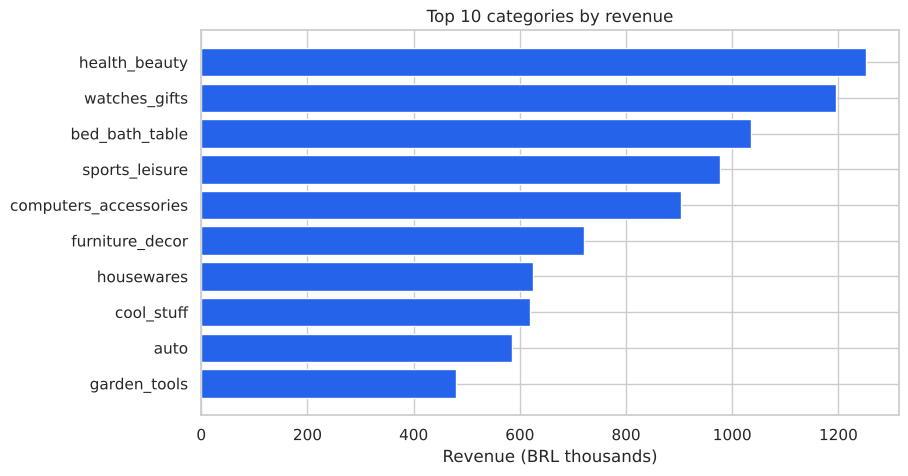

In [5]:
top = c.head(10).sort_values("revenue")
plt.figure(figsize=(9, 5)); plt.barh(top["category"], top["revenue"] / 1e3, color="#2563eb")
plt.title("Top 10 categories by revenue"); plt.xlabel("Revenue (BRL thousands)");
print(f"Top 5 categories = {c.head(5)['revenue_share'].sum():.1%} of revenue")

No single category dominates. The top five make up about 40% of revenue, which is a healthy spread. Health and beauty, watches and gifts, and bed, bath and table lead.

## Freight cost by category
High freight relative to price can put customers off. Electronics and furniture have the heaviest shipping burden.

In [6]:
f = c[c["orders"] >= 500].sort_values("freight_to_price", ascending=False).head(8)
f[["category", "avg_price", "avg_freight", "freight_to_price", "avg_review"]]

,category,avg_price,avg_freight,freight_to_price,avg_review
21,electronics,57.00,16.82,0.30,4.03
14,office_furniture,161.69,40.50,0.25,3.49
5,furniture_decor,87.69,20.76,0.24,3.91
6,housewares,90.62,21.00,0.23,4.06
13,telephony,71.29,15.68,0.22,3.94
25,luggage_accessories,128.78,27.93,0.22,4.32
22,fashion_bags_accessories,75.02,15.46,0.21,4.14
9,garden_tools,110.95,22.76,0.21,4.04


## Payment methods

In [7]:
pd.read_csv(OUT / "payment_summary.csv")

,payment_type,orders,aov,order_share
0,credit_card,73891,143.61,0.75
1,boleto,19479,121.68,0.20
2,voucher,3028,94.89,0.03
3,debit_card,1512,119.64,0.02


Credit card is about three quarters of orders. Boleto (a Brazilian bank slip) is the second largest at about 20%, so supporting it matters in this market.